# Лабораторная работа 2. Текстовое ранжирование: TF-IDF и BM25 на WikiQA
##  Cтудент

**ФИО:** Моцпан Софья
**Группа:** ИНФА-231
**Вариант:** 8

---

**Цель работы:** освоить построение и сравнение классических алгоритмов текстового
ранжирования TF-IDF и BM25 на англоязычном корпусе, научиться вычислять DCG/NDCG
и интерпретировать причины различий поисковой выдачи.

**Постановка задачи.** Для английского вопроса требуется расположить предложения
связанной статьи Wikipedia так, чтобы предложения, содержащие правильный ответ,
оказались как можно выше в выдаче.

**Как работать с ноутбуком**

1. Ячейки с пометкой `# ВЫДАНО` менять не нужно — это инфраструктура.
2. Ячейки с `# TODO` содержат задания. Каждое задание закрывается автотестом
   (`test_*`): пока задание не выполнено, тест падает.
3. В конце есть ячейка «Полная самопроверка» — перед сдачей она должна пройти целиком.
4. Перед сдачей выполните **Kernel → Restart & Run All**: ноутбук обязан
   воспроизводиться сверху вниз без ручных правок.

**Что нельзя делать**

* использовать колонку `Label` при вычислении оценок ранжирования (это утечка
  разметки; автотест её обнаруживает);
* строить индекс только по кандидатам одного вопроса — IDF и средняя длина документа
  считаются по всему выбранному split;
* использовать разную токенизацию для TF-IDF и BM25.

## 1. Настройка окружения и вариант

In [1]:
# ВЫДАНО: установка зависимостей и импорты
import importlib
import re
import subprocess
import sys
import warnings
import zlib

def ensure(packages):
    for module, pip_name in packages.items():
        try:
            importlib.import_module(module)
        except ImportError:
            print(f"[install] {pip_name} ...")
            try:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name],
                               check=True, timeout=300)
            except Exception as exc:                  # noqa: BLE001
                print(f"[warn] не удалось установить {pip_name}: {exc}")

ensure({"rank_bm25": "rank-bm25", "sklearn": "scikit-learn",
        "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib"})
ensure({"kagglehub": "kagglehub"})

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import ndcg_score

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
warnings.filterwarnings("ignore", category=FutureWarning)
print("Окружение готово. Python", sys.version.split()[0])

[install] rank-bm25 ...
Окружение готово. Python 3.13.18


In [2]:
# ВЫДАНО: параметры индивидуального варианта
B_GRID = [0.60, 0.70, 0.75, 0.80, 0.85]

def get_variant(v: int) -> dict:
    if not 1 <= int(v) <= 25:
        raise ValueError("Номер варианта должен быть в диапазоне 1..25")
    v = int(v)
    return {"variant": v,
            "k1": round(1.2 + 0.2 * ((v - 1) // 5), 1),
            "b": B_GRID[(v - 1) % 5],
            "k": 5 if v % 2 == 1 else 10}

# ------------------------------------------------------------------
VARIANT = 8          # <-- ЗАМЕНИТЕ на номер своего варианта (1..25)
# ------------------------------------------------------------------
PARAMS = get_variant(VARIANT)
K1, B, K = PARAMS["k1"], PARAMS["b"], PARAMS["k"]
print(f"Вариант {VARIANT}: k1 = {K1}, b = {B}, метрика NDCG@{K}")

Вариант 8: k1 = 1.4, b = 0.75, метрика NDCG@10


## 2. Данные: Microsoft Research WikiQA Corpus

Единица **документа** в этой работе — одно предложение-кандидат (`Sentence`),
**запрос** — англоязычный вопрос (`Question`), **истинная релевантность** — `Label` (0/1).

Схема исходного TSV-файла:

| Поле | Смысл |
|---|---|
| `QuestionID` | идентификатор вопроса (`Q1`, `Q2`, …) |
| `Question` | текст вопроса на английском языке |
| `DocumentID`, `DocumentTitle` | статья Wikipedia, из которой взяты кандидаты |
| `SentenceID` | идентификатор предложения-кандидата |
| `Sentence` | текст предложения-кандидата |
| `Label` | 1 — предложение является ответом, 0 — не является |

Ячейка ниже реализует **три пути загрузки** (выполняются по очереди, до первого успешного):

1. локальный файл `data/wikiqa/WikiQA-test.tsv` (скачан вручную с Microsoft Download Center или с Kaggle);
2. автоматическая загрузка через `kagglehub` (зеркало `saurabhshahane/wikiqa-corpus`) или через `datasets` (`microsoft/wiki_qa`);
3. **синтетический генератор-заглушка** — на случай, когда сети нет вообще.

> ⚠️ Третий путь нужен только для того, чтобы ноутбук гарантированно запускался и код можно было отладить.
> Числа, полученные на синтетических данных, **не являются** результатом лабораторной работы:
> сдавать нужно прогон на настоящем WikiQA (переменная `DATA_SOURCE` должна быть `local`, `kagglehub` или `huggingface`).

In [3]:
# ============================================================================
#  Загрузка WikiQA: три пути (локальный файл -> сеть -> синтетическая заглушка)
# ============================================================================
import os
import glob
import random
import warnings

import numpy as np
import pandas as pd

WIKIQA_COLUMNS = ["QuestionID", "Question", "DocumentID", "DocumentTitle",
                  "SentenceID", "Sentence", "Label"]

# Справочные размеры настоящего корпуса (Yang, Yih, Meek, EMNLP 2015)
WIKIQA_REFERENCE = {
    "train": {"questions": 2118, "sentences": 20360, "answers": 1040},
    "dev":   {"questions": 296,  "sentences": 2733,  "answers": 140},
    "test":  {"questions": 633,  "sentences": 6165,  "answers": 293},
}

DATA_SOURCE = None  # заполняется функцией load_wikiqa()


def _normalize(df):
    """Приводит датафрейм к каноническому набору колонок WIKIQA_COLUMNS."""
    df = df.copy()
    rename = {"question_id": "QuestionID", "question": "Question",
              "document_title": "DocumentTitle", "answer": "Sentence",
              "label": "Label", "sentence": "Sentence"}
    df = df.rename(columns={c: rename[c] for c in df.columns if c in rename})
    if "DocumentID" not in df.columns:
        df["DocumentID"] = df.get("DocumentTitle", pd.Series(["D0"] * len(df)))
    if "SentenceID" not in df.columns:
        df["SentenceID"] = [f"{q}-{i}" for i, q in enumerate(df["QuestionID"])]
    df["Label"] = df["Label"].astype(int)
    for col in ("Question", "Sentence", "DocumentTitle"):
        df[col] = df[col].astype(str)
    return df[WIKIQA_COLUMNS].reset_index(drop=True)


def _load_local(split, data_dir):
    """Путь 1. Локальный TSV-файл из официального архива WikiQACorpus."""
    patterns = [
        os.path.join(data_dir, f"WikiQA-{split}.tsv"),
        os.path.join(data_dir, "**", f"WikiQA-{split}.tsv"),
        os.path.join("**", f"WikiQA-{split}.tsv"),
    ]
    for pattern in patterns:
        hits = sorted(glob.glob(pattern, recursive=True))
        if hits:
            return _normalize(pd.read_csv(hits[0], sep="\t", quoting=3)), hits[0]
    return None, None


def _load_kagglehub(split):
    """Путь 2а. Kaggle-зеркало (kagglehub скачивает архив в локальный кэш)."""
    import kagglehub
    path = kagglehub.dataset_download("saurabhshahane/wikiqa-corpus")
    hits = sorted(glob.glob(os.path.join(path, "**", f"WikiQA-{split}.tsv"),
                            recursive=True))
    if not hits:
        raise FileNotFoundError(f"WikiQA-{split}.tsv не найден в {path}")
    return _normalize(pd.read_csv(hits[0], sep="\t", quoting=3)), hits[0]


def _load_huggingface(split):
    """Путь 2б. Hugging Face Hub: microsoft/wiki_qa."""
    from datasets import load_dataset
    hf_split = {"dev": "validation"}.get(split, split)
    ds = load_dataset("microsoft/wiki_qa", split=hf_split)
    return _normalize(ds.to_pandas()), "huggingface:microsoft/wiki_qa"


# ---------------------------------------------------------------------------
#  Путь 3. Синтетическая заглушка, имитирующая структуру и статистику WikiQA
# ---------------------------------------------------------------------------
_SYN_TOPICS = [
    ("Glacier cave", ["glacier", "meltwater", "crevasse", "ice", "tunnel"]),
    ("Harpsichord", ["keyboard", "plectrum", "strings", "baroque", "jack"]),
    ("Monsoon", ["rainfall", "wind", "seasonal", "tropics", "humidity"]),
    ("Lighthouse", ["beacon", "coast", "lantern", "keeper", "navigation"]),
    ("Penicillin", ["antibiotic", "mould", "bacteria", "infection", "culture"]),
    ("Sundial", ["gnomon", "shadow", "hours", "dial", "solar"]),
    ("Aqueduct", ["channel", "water", "arches", "roman", "gradient"]),
    ("Kiwi bird", ["flightless", "burrow", "nocturnal", "beak", "forest"]),
    ("Tundra", ["permafrost", "arctic", "lichen", "shrub", "soil"]),
    ("Zeppelin", ["airship", "hydrogen", "rigid", "hull", "flight"]),
    ("Sonar", ["acoustic", "echo", "submarine", "pulse", "underwater"]),
    ("Kimchi", ["fermented", "cabbage", "korean", "chilli", "jar"]),
    ("Obsidian", ["volcanic", "glass", "lava", "fracture", "blade"]),
    ("Morse code", ["telegraph", "dots", "dashes", "signal", "operator"]),
    ("Coral reef", ["polyp", "calcium", "lagoon", "tropical", "bleaching"]),
    ("Windmill", ["sails", "grain", "milling", "rotor", "tower"]),
    ("Vaccine", ["immunity", "antigen", "dose", "clinical", "virus"]),
    ("Cuneiform", ["clay", "tablet", "stylus", "sumerian", "script"]),
    ("Geyser", ["eruption", "groundwater", "steam", "vent", "basin"]),
    ("Espresso", ["pressure", "portafilter", "crema", "roast", "grind"]),
    ("Bagpipes", ["drone", "chanter", "reed", "highland", "bag"]),
    ("Permaculture", ["agriculture", "design", "guild", "mulch", "yield"]),
    ("Semaphore", ["flags", "visual", "signalling", "arms", "station"]),
    ("Plate tectonics", ["lithosphere", "subduction", "mantle", "drift", "fault"]),
    ("Origami", ["folding", "paper", "crease", "model", "japanese"]),
    ("Quinine", ["malaria", "bark", "alkaloid", "tonic", "treatment"]),
    ("Lacrosse", ["stick", "netting", "team", "goal", "field"]),
    ("Pidgin language", ["contact", "grammar", "trade", "speakers", "simplified"]),
    ("Cartography", ["projection", "scale", "map", "survey", "legend"]),
    ("Hovercraft", ["cushion", "skirt", "fan", "amphibious", "craft"]),
]

_SYN_ASPECTS = [
    ("origin", "how is the {f} of a {t} formed", ["formed", "formation", "forms"],
     ["arises", "develops", "emerges"]),
    ("definition", "what is the {f} of {t}", ["term", "refers", "defined"],
     ["denotes", "describes", "means"]),
    ("location", "where is the {f} of {t} found", ["located", "situated", "region"],
     ["lies", "occurs", "distributed"]),
    ("time", "when was the {f} of {t} first described", ["first", "described", "century"],
     ["initially", "documented", "recorded"]),
    ("person", "who invented the {t} {f}", ["invented", "inventor", "engineer"],
     ["devised", "pioneer", "credited"]),
    ("size", "how big is the {f} of a {t}", ["metres", "diameter", "large"],
     ["measures", "span", "extent"]),
    ("purpose", "what is the {f} of {t} used for", ["used", "purpose", "application"],
     ["serves", "employed", "role"]),
    ("cause", "what causes the {f} of {t}", ["caused", "cause", "results"],
     ["triggered", "produced", "driven"]),
]

_SYN_FILLER = (
    "the of and in to a is was for with on as by are from that at it this "
    "which or an be were has have been also often usually most many some "
    "such other than more into between during after before over under "
    "modern early late common known called including example although "
    "however typically generally particularly widely small large narrow "
    "wide long short heavy light natural artificial local regional "
    "surface material structure system process design method number "
    "period record study report century year time part group area"
).split()


def _syn_sentence(rng, title_tokens, topic_words, cues, length):
    """Собирает предложение заданной длины из тематических и служебных слов."""
    tokens = list(title_tokens) + list(topic_words) + list(cues)
    while len(tokens) < length:
        # частотный «хвост»: короткие служебные слова встречаются чаще
        idx = min(int(abs(rng.gauss(0, 0.35)) * len(_SYN_FILLER)), len(_SYN_FILLER) - 1)
        tokens.append(_SYN_FILLER[idx])
    rng.shuffle(tokens)
    text = " ".join(tokens)
    return text[0].upper() + text[1:] + " ."


def _load_synthetic(split, seed=20261014):
    """Путь 3. Детерминированная имитация WikiQA со схожей статистикой."""
    ref = WIKIQA_REFERENCE.get(split, WIKIQA_REFERENCE["test"])
    n_questions = ref["questions"]
    rng = random.Random(seed + len(split))
    rows = []
    for qi in range(n_questions):
        title, topic_vocab = _SYN_TOPICS[rng.randrange(len(_SYN_TOPICS))]
        aspect, tmpl, cues, syn_cues = _SYN_ASPECTS[rng.randrange(len(_SYN_ASPECTS))]
        title_tokens = title.lower().split()
        focus = rng.choice(topic_vocab)               # содержательное слово вопроса
        others = [w for w in topic_vocab if w != focus]
        question = tmpl.format(t=title.lower(), f=focus)
        # доля вопросов без единого правильного ответа ~ как в настоящем WikiQA
        has_answer = rng.random() < (243 / 633)
        n_cand = max(2, int(rng.gauss(9.7, 3.5)))
        n_pos = rng.randint(1, 2) if has_answer else 0
        pos_slots = set(rng.sample(range(n_cand), k=min(n_pos, n_cand)))
        # четверть правильных ответов выражена синонимами, а не словами вопроса
        paraphrase = rng.random() < 0.25
        for si in range(n_cand):
            topic_words = rng.sample(others, k=min(len(others), rng.randint(1, 3)))
            if si in pos_slots:
                label = 1
                if paraphrase:                        # лексический разрыв
                    sent_cues = rng.sample(syn_cues, k=min(2, len(syn_cues)))
                else:
                    sent_cues = rng.sample(cues, k=min(2, len(cues))) + [focus]
            else:
                label = 0
                sent_cues = []
                if rng.random() < 0.30:               # «трудный» отрицательный
                    sent_cues.append(rng.choice(cues))
                if rng.random() < 0.25:
                    sent_cues.append(focus)
                if rng.random() < 0.12:               # «переспам»: слово вопроса 2-4 раза
                    sent_cues += [focus] * rng.randint(2, 4)
            length = max(6, int(rng.gauss(25, 11)))   # средняя длина ~25 токенов
            rows.append({
                "QuestionID": f"S{qi + 1}",
                "Question": question,
                "DocumentID": f"D{qi + 1}",
                "DocumentTitle": title,
                "SentenceID": f"S{qi + 1}-{si}",
                "Sentence": _syn_sentence(rng, title_tokens, topic_words,
                                          sent_cues, length),
                "Label": label,
            })
    return _normalize(pd.DataFrame(rows)), "synthetic"


def load_wikiqa(split="test", data_dir="data/wikiqa", allow_synthetic=True,
                verbose=True):
    """Возвращает (DataFrame, источник). Порядок: локально -> сеть -> заглушка."""
    global DATA_SOURCE
    attempts = [
        ("local", lambda: _load_local(split, data_dir)),
        ("kagglehub", lambda: _load_kagglehub(split)),
        ("huggingface", lambda: _load_huggingface(split)),
    ]
    for name, fn in attempts:
        try:
            df, origin = fn()
            if df is not None and len(df) > 0:
                DATA_SOURCE = name
                if verbose:
                    print(f"[OK] Источник данных: {name} ({origin})")
                return df, name
        except Exception as exc:                      # noqa: BLE001
            if verbose:
                print(f"[--] {name}: {type(exc).__name__}: {exc}")
    if not allow_synthetic:
        raise RuntimeError(
            "Настоящий WikiQA не найден. Скачайте WikiQACorpus.zip и положите "
            "WikiQA-test.tsv в data/wikiqa/, либо установите kagglehub/datasets."
        )
    df, _ = _load_synthetic(split)
    DATA_SOURCE = "synthetic"
    warnings.warn("Используется СИНТЕТИЧЕСКАЯ заглушка: результаты не засчитываются "
                  "как выполнение лабораторной работы.", stacklevel=2)
    if verbose:
        print("[!!] Источник данных: synthetic (заглушка, только для отладки кода)")
    return df, "synthetic"


def describe_corpus(df, split="test"):
    """Печатает статистику загруженного корпуса и сверяет её со справочной."""
    n_q = df["QuestionID"].nunique()
    n_s = len(df)
    n_a = int(df["Label"].sum())
    per_q = df.groupby("QuestionID")["Label"].agg(["size", "sum"])
    n_q_with_answer = int((per_q["sum"] > 0).sum())
    print(f"Вопросов:                      {n_q}")
    print(f"Предложений-кандидатов:        {n_s}")
    print(f"Предложений с Label=1:         {n_a}")
    print(f"Вопросов, где есть ответ:      {n_q_with_answer} "
          f"({n_q_with_answer / max(n_q, 1):.1%})")
    print(f"Кандидатов на вопрос (сред.):  {per_q['size'].mean():.2f} "
          f"[{per_q['size'].min()}..{per_q['size'].max()}]")
    print(f"Длина предложения (токенов):   "
          f"{df['Sentence'].str.split().str.len().mean():.2f}")
    ref = WIKIQA_REFERENCE.get(split)
    if ref:
        ok = (n_q == ref["questions"] and n_s == ref["sentences"]
              and n_a == ref["answers"])
        print(f"\nСправочные значения WikiQA-{split}: "
              f"{ref['questions']} вопросов / {ref['sentences']} предложений / "
              f"{ref['answers']} ответов")
        print("Совпадение со справочными значениями:", "ДА" if ok else "НЕТ")
    return per_q

In [4]:
# ВЫДАНО: загрузка корпуса и базовая статистика
SPLIT = "test"
df, source = load_wikiqa(split=SPLIT, data_dir="data/wikiqa", allow_synthetic=True)
df = df.reset_index(drop=True)
describe_corpus(df, split=SPLIT)
df.head(5)

Using Colab cache for faster access to the 'wikiqa-corpus' dataset.
[OK] Источник данных: kagglehub (/kaggle/input/wikiqa-corpus/WikiQA-test.tsv)
Вопросов:                      633
Предложений-кандидатов:        6165
Предложений с Label=1:         293
Вопросов, где есть ответ:      243 (38.4%)
Кандидатов на вопрос (сред.):  9.74 [1..30]
Длина предложения (токенов):   22.42

Справочные значения WikiQA-test: 633 вопросов / 6165 предложений / 293 ответов
Совпадение со справочными значениями: ДА


,QuestionID,Question,DocumentID,DocumentTitle,SentenceID,Sentence,Label
0,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-0,African immigration to the United States refers to immigrants to the United States who...,0
1,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-1,The term African in the scope of this article refers to geographical or national origi...,0
2,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-2,"From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to...",0
3,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-3,African immigrants in the United States come from almost all regions in Africa and do ...,0
4,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-4,"They include people from different national, linguistic, ethnic, racial, cultural and ...",0


## 2. Задание 1. Исследование candidate sets

Ответьте на вопросы (числами, полученными из данных, а не из README):

1. Сколько всего вопросов и сколько предложений-кандидатов в загруженном split?
633 вопроса
2. У какой доли вопросов есть хотя бы одно предложение с `Label = 1`?
38.389%
3. Каково среднее число кандидатов на вопрос и средняя длина предложения? 9.74
4. Выведите все кандидаты одного вопроса, у которого есть правильный ответ,
   и пометьте правильные предложения. 22.42

Почему это важно: все кандидаты одного вопроса взяты из одной и той же статьи
Wikipedia, поэтому слова из заголовка статьи почти не различают кандидатов.

In [6]:
# TODO 1: разведочный анализ candidate sets
stats = (
    df.groupby("QuestionID", sort=False)
      .agg(Question=("Question", "first"),
           candidates=("SentenceID", "size"),
           relevant=("Label", "sum"))
)
stats["has_answer"] = stats["relevant"] > 0

n_questions = df["QuestionID"].nunique()
n_sentences = len(df)
answer_share = stats["has_answer"].mean()
mean_candidates = stats["candidates"].mean()
mean_sentence_length = df["Sentence"].str.split().str.len().mean()

print(f"Вопросов: {n_questions}")
print(f"Предложений-кандидатов: {n_sentences}")
print(f"Доля вопросов хотя бы с одним ответом: {answer_share:.3%}")
print(f"Среднее число кандидатов на вопрос: {mean_candidates:.2f}")
print(f"Средняя длина предложения (слов): {mean_sentence_length:.2f}")

# Показываем все кандидаты первого вопроса, для которого существует ответ.
example_qid = stats.index[stats["has_answer"]][0]
example = df[df["QuestionID"] == example_qid][
    ["QuestionID", "Question", "SentenceID", "Sentence", "Label"]
].copy()
example["Релевантность"] = np.where(example["Label"].eq(1), "ОТВЕТ", "не ответ")
print(f"\nПример candidate set: {example_qid}")
display(example)

Вопросов: 633
Предложений-кандидатов: 6165
Доля вопросов хотя бы с одним ответом: 38.389%
Среднее число кандидатов на вопрос: 9.74
Средняя длина предложения (слов): 22.42

Пример candidate set: Q0


,QuestionID,Question,SentenceID,Sentence,Label,Релевантность
0,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0-0,African immigration to the United States refers to immigrants to the United States who...,0,не ответ
1,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0-1,The term African in the scope of this article refers to geographical or national origi...,0,не ответ
2,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0-2,"From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to...",0,не ответ
3,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0-3,African immigrants in the United States come from almost all regions in Africa and do ...,0,не ответ
4,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0-4,"They include people from different national, linguistic, ethnic, racial, cultural and ...",0,не ответ
5,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0-5,"As such, African immigrants are to be distinguished from African American people, the ...",1,ОТВЕТ


## 3. Задание 2. Единая токенизация

`rank_bm25` **не выполняет предобработку самостоятельно**: запрос нужно обрабатывать
точно так же, как документы. Поэтому напишем один токенизатор и будем передавать его
и в `TfidfVectorizer` (через параметр `analyzer`), и в BM25.

Требования к `tokenize`:

* приводит текст к нижнему регистру;
* оставляет только последовательности букв и цифр (пунктуация отбрасывается);
* при `remove_stopwords=True` убирает английские стоп-слова из `ENGLISH_STOPWORDS`
  (вопросительные слова *how, what, when, who* в этот список намеренно **не** включены —
  посмотрите в разборе запросов, помогают они или мешают);
* возвращает **список** токенов.

In [7]:
# ВЫДАНО: список стоп-слов и заготовка регулярного выражения
TOKEN_RE = re.compile(r"[a-z0-9]+")

ENGLISH_STOPWORDS = frozenset("""
a an the and or but if then than that this these those there here of in on at to
for with without within from by as is are was were be been being am do does did
doing have has had having will would shall should can could may might must
it its it's he she they them his her their our your my me we you i not no nor so
such about into over under again further once during before after above below
""".split())


# TODO 2: реализуйте токенизацию
def tokenize(text, remove_stopwords: bool = True, stem: bool = False):
    """Нижний регистр, буквенно-цифровые токены, опциональные стоп-слова."""
    tokens = TOKEN_RE.findall(str(text).lower())
    if remove_stopwords:
        tokens = [token for token in tokens if token not in ENGLISH_STOPWORDS]
    # stem оставлен для дополнительного исследования; в основной работе False.
    if stem:
        try:
            from nltk.stem import PorterStemmer
        except ImportError as exc:
            raise ImportError("Для stem=True установите nltk") from exc
        stemmer = PorterStemmer()
        tokens = [stemmer.stem(token) for token in tokens]
    return tokens


def make_tokenizer(remove_stopwords=True, stem=False):
    """ВЫДАНО: фабрика токенизаторов для TfidfVectorizer и BM25."""
    def _tok(text):
        return tokenize(text, remove_stopwords=remove_stopwords, stem=stem)
    return _tok


TOKENIZER = make_tokenizer(remove_stopwords=True, stem=False)

In [8]:
# ВЫДАНО: автотест задания 2
def test_tokenize():
    assert tokenize("The Glacier Caves were formed!") == ["glacier", "caves", "formed"], \
        "проверьте нижний регистр, пунктуацию и удаление стоп-слов"
    assert tokenize("The 1889 Paris Exposition!") == ["1889", "paris", "exposition"], \
        "цифры должны сохраняться"
    assert tokenize("the of and in to") == [], "стоп-слова должны удаляться"
    assert tokenize("The of and", remove_stopwords=False) == ["the", "of", "and"], \
        "при remove_stopwords=False стоп-слова остаются"
    assert isinstance(tokenize("test"), list), "функция должна возвращать список"
    assert TOKENIZER("A lighthouse.") == tokenize("A lighthouse."), \
        "TOKENIZER должен совпадать с tokenize"
    print("test_tokenize: OK")

test_tokenize()

test_tokenize: OK


## 4. Задание 3. TF-IDF

`TfidfVectorizer` строит матрицу «документ × терм». При `norm="l2"` строки нормированы,
поэтому скалярное произведение вектора вопроса и вектора предложения равно косинусной
близости:

$$\cos(q,d)=\frac{\langle q,d\rangle}{\lVert q\rVert\lVert d\rVert}=\langle\hat q,\hat d\rangle$$

**Важно:** индекс строится по **всем** предложениям split (чтобы IDF был
общекорпусным), а ранжируются только кандидаты конкретного вопроса.

In [9]:
# TODO 3: постройте индекс TF-IDF и функцию оценки (по ВСЕМ предложениям выбранного split)
SENTENCES = df["Sentence"].tolist()

tfidf_vectorizer = TfidfVectorizer(analyzer=TOKENIZER, norm="l2")
TFIDF_MATRIX = tfidf_vectorizer.fit_transform(SENTENCES)


def tfidf_scorer(question, candidate_idx):
    """Косинусная близость вопроса и кандидатов."""
    q_vector = tfidf_vectorizer.transform([question])
    candidate_idx = np.asarray(candidate_idx, dtype=int)
    # При L2-нормировке строк скалярное произведение равно cosine similarity.
    return np.asarray(TFIDF_MATRIX[candidate_idx].dot(q_vector.T).toarray()).ravel()

In [10]:
# ВЫДАНО: автотест задания 3
def test_tfidf():
    assert TFIDF_MATRIX is not None and TFIDF_MATRIX.shape[0] == len(df), \
        "индекс должен быть построен по ВСЕМ предложениям split"
    qid = df.loc[df["Label"] == 1, "QuestionID"].iloc[0]
    idx = df.index[df["QuestionID"] == qid].to_numpy()
    scores = np.asarray(tfidf_scorer(df.loc[idx[0], "Question"], idx), dtype=float)
    assert scores.shape == (len(idx),), "длина ответа должна совпадать с числом кандидатов"
    assert np.all(scores >= -1e-9) and np.all(scores <= 1 + 1e-9), \
        "косинусная близость неотрицательных векторов лежит в [0, 1]"
    self_query = df.loc[idx[0], "Sentence"]          # запрос = сам первый кандидат
    self_scores = np.asarray(tfidf_scorer(self_query, idx), dtype=float)
    assert int(np.argmax(self_scores)) == 0, \
        "если запрос дословно совпал с кандидатом, он должен получить максимальную оценку"
    print("test_tfidf: OK")

test_tfidf()

test_tfidf: OK


### Служебный код: векторизованный BM25

Ячейка ниже — **выдана готовой**, изменять её не нужно. Она решает две задачи:

* даёт быструю (матричную) реализацию BM25 Okapi, с помощью которой считаются
  «сетки» по параметрам $k_1, b$ — библиотечный `BM25Okapi` пришлось бы вызывать
  тысячи раз, и это было бы медленно;
* служит **аварийным запасным вариантом**, если `rank_bm25` не установился
  (например, в аудитории нет интернета).

Формула здесь та же, что и в `rank_bm25`, включая обработку отрицательных IDF:

$$\mathrm{IDF}(q)=\ln\frac{N-n(q)+0.5}{n(q)+0.5},\qquad
\mathrm{BM25}(D,Q)=\sum_{q\in Q}\mathrm{IDF}(q)\,
\frac{f(q,D)\,(k_1+1)}{f(q,D)+k_1\left(1-b+b\frac{|D|}{\mathrm{avgdl}}\right)}$$

Совпадение с библиотекой проверяется автотестом ниже (расхождение должно быть < 1e-9).

In [11]:
# ============================================================================
#  Служебный код (выдан готовым): векторизованный BM25 Okapi
# ============================================================================
import numpy as np
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer

try:
    from rank_bm25 import BM25Okapi
    HAS_RANK_BM25 = True
except ImportError:                                   # pragma: no cover
    BM25Okapi = None
    HAS_RANK_BM25 = False
    print("[!] Библиотека rank_bm25 не установлена: используется запасная "
          "реализация BM25Fast. Для сдачи работы установите rank-bm25.")


class BM25Fast:
    """BM25 Okapi на разреженной матрице частот. Совместим с rank_bm25.BM25Okapi.

    Parameters
    ----------
    corpus : list[str]           тексты документов (предложений-кандидатов)
    tokenizer : callable         та же токенизация, что и для запросов
    k1, b, epsilon : float       параметры BM25 (epsilon — как в rank_bm25)
    """

    def __init__(self, corpus, tokenizer, k1=1.5, b=0.75, epsilon=0.25):
        self.k1, self.b, self.epsilon = float(k1), float(b), float(epsilon)
        self.tokenizer = tokenizer
        self.vectorizer = CountVectorizer(analyzer=tokenizer)
        self.tf = self.vectorizer.fit_transform(corpus).tocsr().astype(np.float64)
        self.vocab = self.vectorizer.vocabulary_
        self.doc_len = np.asarray(self.tf.sum(axis=1)).ravel()
        self.avgdl = float(self.doc_len.mean())
        n_docs = self.tf.shape[0]
        doc_freq = np.asarray((self.tf > 0).sum(axis=0)).ravel().astype(np.float64)
        idf = np.log(n_docs - doc_freq + 0.5) - np.log(doc_freq + 0.5)
        average_idf = float(idf.mean())
        idf[idf < 0] = self.epsilon * average_idf      # как в rank_bm25
        self.idf = idf
        self._denom_len = self.k1 * (1.0 - self.b + self.b * self.doc_len / self.avgdl)

    def _query_columns(self, query_tokens):
        return [self.vocab[t] for t in query_tokens if t in self.vocab]

    def score_candidates(self, query, candidate_idx):
        """Оценки BM25 только для указанных строк корпуса (быстрый путь)."""
        cols = self._query_columns(self.tokenizer(query))
        candidate_idx = np.asarray(candidate_idx, dtype=int)
        if not cols:
            return np.zeros(len(candidate_idx))
        sub = self.tf[candidate_idx][:, cols].toarray()          # (n_cand, n_terms)
        denom = sub + self._denom_len[candidate_idx][:, None]
        contrib = np.asarray(self.idf)[cols][None, :] * sub * (self.k1 + 1.0) / denom
        return contrib.sum(axis=1)

    def get_scores(self, query_tokens):
        """Оценки для всего корпуса — сигнатура как у rank_bm25.BM25Okapi."""
        cols = self._query_columns(query_tokens)
        if not cols:
            return np.zeros(self.tf.shape[0])
        sub = self.tf[:, cols].toarray()
        denom = sub + self._denom_len[:, None]
        return (np.asarray(self.idf)[cols][None, :] * sub * (self.k1 + 1.0) / denom).sum(axis=1)

## 5. Задание 4. BM25

$$\mathrm{BM25}(D,Q)=\sum_{q\in Q}\mathrm{IDF}(q)\cdot
\frac{f(q,D)\,(k_1+1)}{f(q,D)+k_1\left(1-b+b\dfrac{\lvert D\rvert}{\mathrm{avgdl}}\right)}$$

Постройте **два** индекса:

* `bm25_default` с параметрами по умолчанию $k_1=1.5$, $b=0.75$;
* `bm25_variant` с параметрами вашего варианта $k_1$, $b$.

Второй индекс нужен, чтобы отделить эффект вашего варианта от эффекта самого
перехода TF-IDF → BM25.

Подсказки:

* `BM25Okapi` принимает корпус как **список списков токенов**, а не список строк;
* `get_scores(query_tokens)` возвращает оценки для **всего** корпуса — нужные
  кандидаты отбираются индексацией;
* запрос токенизируется тем же `TOKENIZER`.

In [12]:
# TODO 4: постройте BM25-индексы и функции оценки (BM25-индексы строятся по всему split, а не по candidate set вопроса)
CORPUS_TOKENS = [TOKENIZER(sentence) for sentence in SENTENCES]        # TODO: список списков токенов по SENTENCES

# BM25Fast использует тот же токенизатор, что и TF-IDF, и реализует
# корректировку отрицательного IDF, принятую в rank_bm25.
bm25_default = BM25Fast(SENTENCES, TOKENIZER, k1=1.5, b=0.75)
bm25_variant = BM25Fast(SENTENCES, TOKENIZER, k1=K1, b=B)


def bm25_default_scorer(question, candidate_idx):
    return bm25_default.score_candidates(question, candidate_idx)


def bm25_variant_scorer(question, candidate_idx):
    return bm25_variant.score_candidates(question, candidate_idx)

In [13]:
# ВЫДАНО: автотест задания 4 (сверка с эталонной векторизованной реализацией)
def test_bm25():
    reference = BM25Fast(SENTENCES, TOKENIZER, k1=K1, b=B)
    reference_default = BM25Fast(SENTENCES, TOKENIZER, k1=1.5, b=0.75)
    qids = df.loc[df["Label"] == 1, "QuestionID"].drop_duplicates().head(15)
    max_diff_v = max_diff_d = 0.0
    for qid in qids:
        idx = df.index[df["QuestionID"] == qid].to_numpy()
        q = df.loc[idx[0], "Question"]
        got_v = np.asarray(bm25_variant_scorer(q, idx), dtype=float)
        got_d = np.asarray(bm25_default_scorer(q, idx), dtype=float)
        assert got_v.shape == (len(idx),), "длина ответа не совпала с числом кандидатов"
        max_diff_v = max(max_diff_v, float(np.abs(got_v - reference.score_candidates(q, idx)).max()))
        max_diff_d = max(max_diff_d, float(np.abs(got_d - reference_default.score_candidates(q, idx)).max()))
    assert max_diff_v < 1e-9, (
        f"BM25 варианта расходится с эталоном (Δ={max_diff_v:.2e}): проверьте k1={K1}, "
        f"b={B} и токенизацию запроса")
    assert max_diff_d < 1e-9, (
        f"BM25 по умолчанию расходится с эталоном (Δ={max_diff_d:.2e})")
    print(f"test_bm25: OK (максимальное расхождение с эталоном {max(max_diff_v, max_diff_d):.1e})")

test_bm25()

test_bm25: OK (максимальное расхождение с эталоном 0.0e+00)


## 6. Задание 5. DCG и NDCG

$$DCG@k=\sum_{i=1}^{k}\frac{2^{rel_i}-1}{\log_2(i+1)},\qquad
NDCG@k=\frac{DCG@k}{IDCG@k}$$

$IDCG@k$ — значение $DCG@k$ при идеальном порядке (все релевантные наверху).

Договорённость: если у вопроса **нет** ни одного релевантного документа, $IDCG@k=0$,
NDCG не определён — функция возвращает `float("nan")`, и такие вопросы исключаются
из усреднения. Заменять их нулём нельзя: тогда метрика начнёт измерять долю вопросов
без ответа, а не качество ранжирования.

In [14]:
# TODO 5: реализуйте метрики
def dcg_at_k(relevances, k):
    """DCG@k для последовательности релевантностей в порядке выдачи."""
    rel = np.asarray(relevances, dtype=float)[:int(k)]
    if len(rel) == 0:
        return 0.0
    discounts = np.log2(np.arange(2, len(rel) + 2))
    gains = np.power(2.0, rel) - 1.0
    return float(np.sum(gains / discounts))


def ndcg_at_k(relevances, k):
    """NDCG@k; nan, если в исходном наборе нет релевантных документов."""
    rel = np.asarray(relevances, dtype=float)
    if not np.any(rel > 0):
        return float("nan")
    ideal = np.sort(rel)[::-1]
    idcg = dcg_at_k(ideal, k)
    if idcg == 0:
        return float("nan")
    return float(dcg_at_k(rel, k) / idcg)

In [15]:
# ВЫДАНО: автотест задания 5 (ручные примеры + сверка с scikit-learn)
def test_metrics():
    assert abs(dcg_at_k([1, 0, 0], 3) - 1.0) < 1e-12, "релевантный на 1-й позиции даёт 1.0"
    assert abs(dcg_at_k([0, 1, 0], 3) - 1 / np.log2(3)) < 1e-12, "проверьте дисконт log2(i+1)"
    assert abs(dcg_at_k([1, 1], 1) - 1.0) < 1e-12, "должны учитываться только первые k позиций"
    assert abs(ndcg_at_k([1, 0, 0, 0], 4) - 1.0) < 1e-12, "идеальный порядок даёт NDCG = 1"
    assert abs(ndcg_at_k([0, 0, 1], 2) - 0.0) < 1e-12, "релевантный ниже отсечки k"
    assert np.isnan(ndcg_at_k([0, 0, 0], 3)), "при отсутствии релевантных верните nan"

    rng = np.random.default_rng(0)
    worst = 0.0
    for _ in range(200):
        n = int(rng.integers(3, 12))
        rel = rng.integers(0, 2, size=n)
        if rel.sum() == 0:
            continue
        scores = rng.normal(size=n)
        order = np.argsort(-scores, kind="stable")
        for kk in (5, 10):
            worst = max(worst, abs(ndcg_at_k(rel[order], kk)
                                   - ndcg_score(rel[None, :], scores[None, :], k=kk)))
    assert worst < 1e-9, f"расхождение с sklearn.metrics.ndcg_score: {worst:.2e}"
    print(f"test_metrics: OK (максимальное расхождение с sklearn {worst:.1e})")

test_metrics()

test_metrics: OK (максимальное расхождение с sklearn 3.3e-16)


## 7. Схема оценивания (выдана готовой)

Функция ранжирования получает только текст вопроса и номера строк кандидатов —
меток она не видит. Это структурная защита от утечки разметки; автотест ниже
дополнительно проверяет, что оценки не меняются при перемешивании `Label`.

In [16]:
# ВЫДАНО: группировка запросов, функция оценивания, детектор утечки
def build_groups(frame):
    groups = []
    for qid, g in frame.groupby("QuestionID", sort=False):
        groups.append({"qid": qid, "question": g["Question"].iloc[0],
                       "title": g["DocumentTitle"].iloc[0],
                       "idx": g.index.to_numpy(), "labels": g["Label"].to_numpy()})
    return groups


def evaluate(scorer, groups, k, per_query=False):
    """Средние DCG@k и NDCG@k по запросам, у которых есть хотя бы один Label=1."""
    rows = []
    for g in groups:
        if g["labels"].sum() == 0:
            continue
        scores = np.asarray(scorer(g["question"], g["idx"]), dtype=float)
        order = np.argsort(-scores, kind="stable")
        rels = g["labels"][order]
        rows.append({"QuestionID": g["qid"], "question": g["question"],
                     "dcg": dcg_at_k(rels, k), "ndcg": ndcg_at_k(rels, k)})
    result = pd.DataFrame(rows)
    if per_query:
        return result
    return {"queries": len(result), "mean_DCG": result["dcg"].mean(),
            "mean_NDCG": result["ndcg"].mean()}


def check_no_label_leakage(scorer, groups, n=25, seed=RANDOM_SEED):
    rng_local = np.random.default_rng(seed)
    sample = [groups[i] for i in rng_local.choice(len(groups), size=min(n, len(groups)),
                                                  replace=False)]
    before = [np.asarray(scorer(g["question"], g["idx"]), dtype=float) for g in sample]
    shuffled = [dict(g, labels=rng_local.permutation(g["labels"])) for g in sample]
    after = [np.asarray(scorer(g["question"], g["idx"]), dtype=float) for g in shuffled]
    return all(np.allclose(a, b) for a, b in zip(before, after))


GROUPS = build_groups(df)
ELIGIBLE = [g for g in GROUPS if g["labels"].sum() > 0]
print(f"Всего запросов: {len(GROUPS)}; пригодных для NDCG: {len(ELIGIBLE)} "
      f"({len(ELIGIBLE) / len(GROUPS):.1%})")

assert check_no_label_leakage(tfidf_scorer, ELIGIBLE), "TF-IDF использует Label — это утечка"
assert check_no_label_leakage(bm25_variant_scorer, ELIGIBLE), "BM25 использует Label — это утечка"
print("Проверка на утечку разметки: OK")

Всего запросов: 633; пригодных для NDCG: 243 (38.4%)
Проверка на утечку разметки: OK


In [17]:
# ВЫДАНО: наивные ориентиры, с которыми сравниваются TF-IDF и BM25
_counts = BM25Fast(SENTENCES, TOKENIZER)      # индекс частот строится один раз
COUNT_MATRIX, COUNT_VOCAB = _counts.tf, _counts.vocab


def random_scorer(question, candidate_idx):
    """Случайный порядок (детерминированный по тексту вопроса)."""
    seed = zlib.crc32(question.encode("utf-8")) % (2 ** 32)
    return np.random.default_rng(seed).random(len(candidate_idx))


def overlap_scorer(question, candidate_idx):
    """Сумма частот терминов запроса в кандидате: без IDF и без нормировки длины."""
    cols = [COUNT_VOCAB[t] for t in TOKENIZER(question) if t in COUNT_VOCAB]
    candidate_idx = np.asarray(candidate_idx)
    if not cols:
        return np.zeros(len(candidate_idx))
    return np.asarray(COUNT_MATRIX[candidate_idx][:, cols].sum(axis=1)).ravel().astype(float)

## 8. Задание 6. Сводная таблица

Постройте таблицу со строками `random`, `overlap`, `TF-IDF`, `BM25 default (1.5, 0.75)`,
`BM25 variant` и колонками `queries`, `mean_DCG@k`, `mean_NDCG@k` для $k=5$ и $k=10$.

Строка с вашим вариантом обязательна; строка `BM25 default` нужна, чтобы отделить
эффект варианта от эффекта перехода TF-IDF → BM25.

,method,k,queries,mean_DCG@k,mean_NDCG@k
0,random,5,243,0.4827,0.4242
1,random,10,243,0.5681,0.4961
2,overlap,5,243,0.7614,0.6847
3,overlap,10,243,0.8007,0.7144
4,TF-IDF (cosine),5,243,0.7004,0.6328
5,TF-IDF (cosine),10,243,0.7575,0.6789
6,"BM25 default (k1=1.5, b=0.75)",5,243,0.7110,0.6428
7,"BM25 default (k1=1.5, b=0.75)",10,243,0.7592,0.6801
8,"BM25 variant 8 (k1=1.4, b=0.75)",5,243,0.7135,0.6453
9,"BM25 variant 8 (k1=1.4, b=0.75)",10,243,0.7617,0.6826


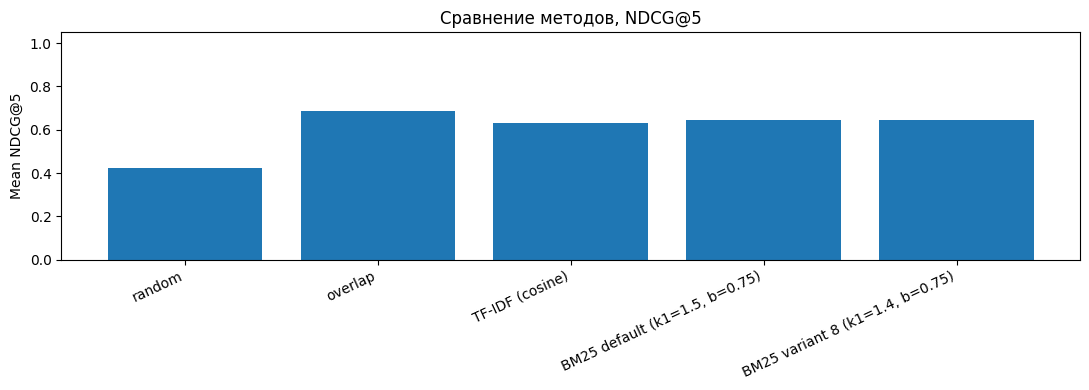

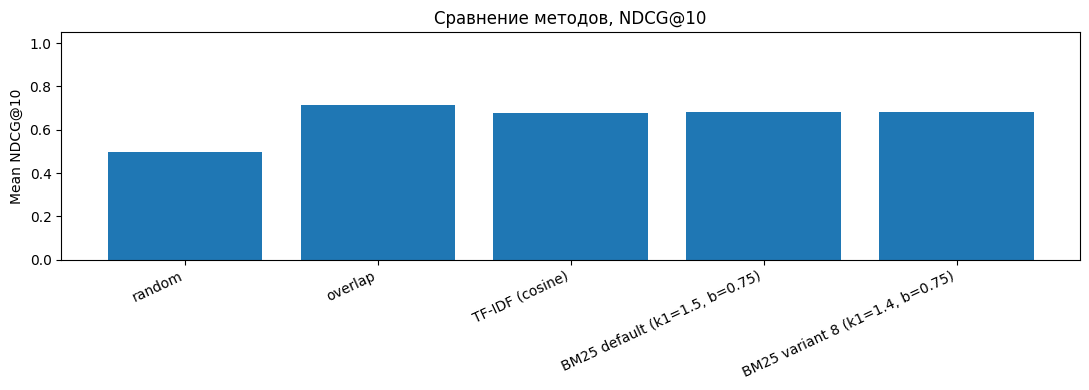

In [19]:
# TODO 6: сводная таблица сравнения методов для k=5 и k=10
METHODS = [
    ("random", random_scorer),
    ("overlap", overlap_scorer),
    ("TF-IDF (cosine)", tfidf_scorer),
    ("BM25 default (k1=1.5, b=0.75)", bm25_default_scorer),
    (f"BM25 variant {VARIANT} (k1={K1}, b={B})", bm25_variant_scorer),
]

comparison_rows = []
for method_name, scorer in METHODS:
    for cutoff in (5, 10):
        result = evaluate(scorer, ELIGIBLE, cutoff)
        comparison_rows.append({
            "method": method_name, "k": cutoff,
            "queries": result["queries"],
            "mean_DCG@k": result["mean_DCG"],
            "mean_NDCG@k": result["mean_NDCG"],
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

for cutoff in (5, 10):
    plot_data = comparison[comparison["k"] == cutoff]
    plt.figure(figsize=(11, 4))
    plt.bar(plot_data["method"], plot_data["mean_NDCG@k"])
    plt.ylabel(f"Mean NDCG@{cutoff}")
    plt.title(f"Сравнение методов, NDCG@{cutoff}")
    plt.xticks(rotation=25, ha="right")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

## 9. Задание 7. Разбор конкретных запросов

Найдите **не менее трёх** вопросов с наибольшим значением
$\left|NDCG_{BM25}-NDCG_{TF\text{-}IDF}\right|$ и для каждого выведите таблицу
кандидатов: `Label`, длина предложения, число совпавших с вопросом терминов,
оценки и позиции обоих методов.

Затем письменно объясните каждый случай. Возможные причины:

* насыщение частоты термина ($k_1$) — повторы одного слова перестают помогать;
* нормировка длины ($b$) — длинные предложения штрафуются иначе, чем при $L_2$;
* редкий термин (имя собственное, год, число) резко поднимает документ;
* **лексический разрыв**: правильный ответ перефразирует вопрос (синонимия,
  морфологическая вариативность, номинализация, смена залога), и оба лексических
  метода ставят его низко.

Последний пункт особенно важен для профиля «Информатика и английский язык»:
прокомментируйте примеры именно с языковой точки зрения.

In [21]:
# TODO 7: per-query анализ расхождений TF-IDF и BM25 variant
pq_tfidf = evaluate(tfidf_scorer, ELIGIBLE, K, per_query=True)
pq_bm25 = evaluate(bm25_variant_scorer, ELIGIBLE, K, per_query=True)

pq_compare = pq_tfidf[["QuestionID", "question", "ndcg"]].merge(
    pq_bm25[["QuestionID", "ndcg"]], on="QuestionID",
    suffixes=("_tfidf", "_bm25")
)
pq_compare["delta"] = pq_compare["ndcg_bm25"] - pq_compare["ndcg_tfidf"]
pq_compare["abs_delta"] = pq_compare["delta"].abs()
top3_qids = pq_compare.nlargest(3, "abs_delta")["QuestionID"].tolist()
print("Три запроса с максимальным |NDCG_BM25 - NDCG_TF-IDF|:")
display(pq_compare.nlargest(3, "abs_delta").round(4))


def show_ranking(qid, top=None):
    """Таблица кандидатов с метками, длиной, overlap, оценками и позициями."""
    g = df[df["QuestionID"] == qid].copy()
    if g.empty:
        raise KeyError(f"Неизвестный QuestionID: {qid}")
    idx = g.index.to_numpy()
    question = g["Question"].iloc[0]
    s_tfidf = tfidf_scorer(question, idx)
    s_bm25 = bm25_variant_scorer(question, idx)
    q_terms = set(TOKENIZER(question))

    out = g[["QuestionID", "SentenceID", "Label", "Sentence"]].copy()
    out["length_tokens"] = out["Sentence"].map(lambda x: len(TOKENIZER(x)))
    out["overlap_terms"] = out["Sentence"].map(
        lambda x: ", ".join(sorted(q_terms.intersection(TOKENIZER(x))))
    )
    out["overlap_count"] = out["Sentence"].map(
        lambda x: len(q_terms.intersection(TOKENIZER(x)))
    )
    out["tfidf_score"] = s_tfidf
    out["bm25_score"] = s_bm25
    out["tfidf_position"] = pd.Series(s_tfidf).rank(
        ascending=False, method="first"
    ).astype(int).to_numpy()
    out["bm25_position"] = pd.Series(s_bm25).rank(
        ascending=False, method="first"
    ).astype(int).to_numpy()
    out = out.sort_values(["bm25_position", "tfidf_position"])
    print(f"QuestionID: {qid}")
    print("Question:", question)
    display(out.reset_index(drop=True))
    positives = out[out["Label"] == 1]
    if len(positives):
        best_tfidf = positives.sort_values("tfidf_position").iloc[0]
        best_bm25 = positives.sort_values("bm25_position").iloc[0]
        print(
            "Лучший релевантный кандидат: "
            f"TF-IDF позиция {int(best_tfidf['tfidf_position'])}, "
            f"BM25 позиция {int(best_bm25['bm25_position'])}."
        )
        print(
            "TF-IDF: длина =", int(best_tfidf["length_tokens"]),
            "; совпавшие термы =", best_tfidf["overlap_terms"] or "нет",
            ". BM25: длина =", int(best_bm25["length_tokens"]),
            "; совпавшие термы =", best_bm25["overlap_terms"] or "нет", "."
        )
    return out


for selected_qid in top3_qids:
    show_ranking(selected_qid)

Три запроса с максимальным |NDCG_BM25 - NDCG_TF-IDF|:


,QuestionID,question,ndcg_tfidf,ndcg_bm25,delta,abs_delta
55,Q757,how many players on a side for a football game,0.4307,1.0000,0.5693,0.5693
151,Q1857,what are private labels,1.0000,0.4307,-0.5693,0.5693
39,Q583,how many days are in a leap year,0.5000,1.0000,0.5000,0.5000


QuestionID: Q757
Question: how many players on a side for a football game


,QuestionID,SentenceID,Label,Sentence,length_tokens,overlap_terms,overlap_count,tfidf_score,bm25_score,tfidf_position,bm25_position
0,Q757,D735-1,1,"It is played by two teams, eleven players to a side, who advance an oval ball over a r...",22,"players, side",2,0.172315,9.030574,4,1
1,Q757,D735-0,0,"American football, known in the United States as football, is a team sport .",8,football,1,0.314958,8.863385,1,2
2,Q757,D735-8,0,"American football evolved from early forms of rugby , particularly rugby union , and a...",12,football,1,0.196686,8.046260,3,3
3,Q757,D735-12,0,"American football is the most popular sport in the United States today, and the Nation...",15,football,1,0.210592,7.525895,2,4
4,Q757,D735-7,0,The team that has scored the most points by the end of the game wins.,7,game,1,0.127935,5.974956,5,5
5,Q757,D735-11,0,"Later rule changes legalized the forward pass , created the neutral zone and specified...",12,football,1,0.111258,5.812438,6,6
6,Q757,D735-9,0,"The first game was played on November 6, 1869 under a set of rules resembling those of...",11,game,1,0.092785,5.151718,7,7
7,Q757,D735-2,0,The team in possession of the ball (the offense) attempts to advance down the field by...,11,,0,0.000000,0.000000,8,8
8,Q757,D735-3,0,"To continue their drive, the offense must advance the ball at least 10 yards down the ...",13,,0,0.000000,0.000000,9,9
9,Q757,D735-4,0,"If they succeed, they receive a new set of four downs to continue their drive.",8,,0,0.000000,0.000000,10,10


Лучший релевантный кандидат: TF-IDF позиция 4, BM25 позиция 1.
TF-IDF: длина = 22 ; совпавшие термы = players, side . BM25: длина = 22 ; совпавшие термы = players, side .
QuestionID: Q1857
Question: what are private labels


,QuestionID,SentenceID,Label,Sentence,length_tokens,overlap_terms,overlap_count,tfidf_score,bm25_score,tfidf_position,bm25_position
0,Q1857,D1756-2,0,Private label goods and services are available in a wide range of industries from food...,12,private,1,0.184358,5.772726,3,1
1,Q1857,D1756-6,0,McBride plc is an example of a European based provider of private label household and ...,12,private,1,0.186149,5.772726,2,2
2,Q1857,D1756-5,0,"Another prominent example is the Cott Corporation , which manufactures private-label b...",13,private,1,0.177680,5.586698,4,3
3,Q1857,D1756-1,1,Private label products or services are typically those manufactured or provided by one...,14,private,1,0.190528,5.412285,1,4
4,Q1857,D1756-0,0,"Swedish grocery store where private label products (under the brands ' and Eldorado , ...",18,private,1,0.133326,4.811446,5,5
5,Q1857,D1756-3,0,"They are often positioned as lower cost alternatives to regional, national or internat...",22,private,1,0.101917,4.330680,6,6
6,Q1857,D1756-4,0,"Richelieu Foods , for example, is a private label company producing frozen pizza, sala...",44,private,1,0.086505,2.794767,7,7


Лучший релевантный кандидат: TF-IDF позиция 1, BM25 позиция 4.
TF-IDF: длина = 14 ; совпавшие термы = private . BM25: длина = 14 ; совпавшие термы = private .
QuestionID: Q583
Question: how many days are in a leap year


,QuestionID,SentenceID,Label,Sentence,length_tokens,overlap_terms,overlap_count,tfidf_score,bm25_score,tfidf_position,bm25_position
0,Q583,D574-4,1,"For example, in the Gregorian calendar (a common solar calendar), February in a leap y...",21,"days, leap, year",3,0.374163,17.323676,3,1
1,Q583,D574-6,0,The term leap year gets its name from the fact that while a fixed date in the Gregoria...,41,"days, leap, year",3,0.414845,16.011204,2,2
2,Q583,D574-3,0,A year that is not a leap year is called a common year .,6,"leap, year",2,0.517040,16.008413,1,3
3,Q583,D574-0,0,A leap year (or intercalary or bissextile year) is a year containing one additional da...,22,"leap, year",2,0.325425,11.856044,4,4
4,Q583,D574-1,0,"Because seasons and astronomical events do not repeat in a whole number of days, a cal...",20,"days, year",2,0.270799,10.665843,5,5
5,Q583,D574-2,0,By occasionally inserting (or intercalating ) an additional day or month into the year...,9,year,1,0.078960,4.613450,6,6
6,Q583,D574-5,0,"Similarly, in the Hebrew calendar (a lunisolar calendar), Adar Aleph , a 13th lunar mo...",27,year,1,0.040628,2.769360,7,7
7,Q583,D574-7,0,"For example, Christmas Day fell on Saturday in 2004, Sunday in 2005, Monday in 2006 an...",17,,0,0.000000,0.000000,8,8


Лучший релевантный кандидат: TF-IDF позиция 3, BM25 позиция 1.
TF-IDF: длина = 21 ; совпавшие термы = days, leap, year . BM25: длина = 21 ; совпавшие термы = days, leap, year .


## Лексический анализ запросов с наибольшим расхождением результатов TF-IDF и BM25

Для подробного анализа были выбраны три вопроса с наибольшей абсолютной разницей между NDCG@10 алгоритмов TF-IDF и BM25. Это запросы Q757, Q1857 и Q583. Их значения абсолютного расхождения составили 0.5693, 0.5693 и 0.5000 соответственно.

### Разбор Q757 («how many players on a side for a football game»)

В данном запросе BM25 показал значительно лучший результат: правильное предложение заняло 1-е место, тогда как TF-IDF поставил его только на 4-е. Разница NDCG@10 составила 0.5693 в пользу BM25.

Правильный кандидат: «It is played by two teams, eleven players to a side, who advance an oval ball over a ...» (22 токена).

С точки зрения лексики это предложение содержит два терма из запроса: players и side. При этом слово football в нём отсутствует. Несмотря на отсутствие прямого совпадения с одним из основных слов вопроса, предложение передаёт необходимую информацию посредством конструкции «eleven players to a side», которая непосредственно отвечает на вопрос о количестве игроков в одной команде.

TF-IDF поставил на первое место предложение «American football, known in the United States as football, is a team sport» (8 токенов). Оно содержит только один совпадающий терм — football, но за счёт короткой длины и высокой концентрации совпадающего слова получило оценку 0.314958. Правильное предложение получило оценку 0.172315.

BM25, напротив, оценил правильный кандидат выше остальных: его оценка составила 9.030574. Здесь важную роль сыграло наличие двух совпадающих термов — players и side. Эти слова непосредственно связаны с содержанием вопроса и позволяют определить ответ, даже несмотря на отсутствие слова football.

Таким образом, данный пример показывает, что простое лексическое сходство не всегда соответствует смысловой релевантности. TF-IDF отдаёт преимущество короткому предложению с прямым совпадением football, тогда как BM25 лучше выделяет предложение, содержащее лексику, непосредственно связанную с искомой информацией. В результате правильный ответ переместился с 4-го на 1-е место.

### Разбор Q1857 («what are private labels»)

В этом запросе наблюдается обратная ситуация: TF-IDF поставил правильное предложение на 1-е место, а BM25 опустил его на 4-е. Разница NDCG@10 составила 0.5693 в пользу TF-IDF.

Правильный кандидат: «Private label products or services are typically those manufactured or provided by one ...» (14 токенов).

Особенность данного примера заключается в том, что все семь кандидатов имеют одинаковое лексическое пересечение с вопросом — только один терм, private. Следовательно, алгоритмам приходится различать предложения преимущественно по весу совпадающего терма и особенностям длины документов.

TF-IDF присвоил правильному предложению оценку 0.190528, что стало наибольшим значением среди кандидатов. При этом предложение содержит определительную конструкцию «Private label products or services are typically those...». Именно она делает его релевантным: автор не просто упоминает private labels, а объясняет, что представляют собой товары и услуги под частной торговой маркой.

BM25 поставил правильное предложение только на 4-е место. Выше оказались три более коротких кандидата длиной 12, 12 и 13 токенов. Например, предложение «Private label goods and services are available in a wide range of industries from food...» имеет 12 токенов и не даёт полноценного определения понятия, хотя содержит тот же совпадающий терм private.

Причина различия связана с нормировкой длины документа в BM25. При параметре b = 0.75 длина предложения влияет на итоговую оценку: более короткие документы могут получать преимущество при одинаковом совпадающем терме. В данном случае правильное предложение длиной 14 токенов уступило нескольким более коротким кандидатам.

TF-IDF, напротив, сохранил преимущество за правильным предложением благодаря общей структуре его вектора и распределению весов терминов. Результат показывает, что учёт длины документа не всегда у лучшает ранжирование: короткое предложение может оказаться выше полноценного определения, хотя последнее лучше отвечает на вопрос.

Дополнительно здесь проявляется морфологическая особенность английского языка: в вопросе используется форма labels, тогда как в предложениях встречается label. При лексической токенизации эти формы рассматриваются как разные термы. Поэтому совпадение private становится главным общим сигналом для всех кандидатов, а морфологическая нормализация могла бы изменить характер пересечения.

### Разбор Q583 («how many days are in a leap year»)

В данном случае BM25 также оказался эффективнее TF-IDF: правильное предложение заняло 1-е место вместо 3-го. Разница NDCG@10 составила 0.5000.

Правильный кандидат: «For example, in the Gregorian calendar (a common solar calendar), February in a leap y...» (21 токен).

Он содержит три совпадающих терма: days, leap и year. При этом предложение использует конкретный пример — February in a leap year, то есть рассматривает вопрос через календарный контекст.

TF-IDF присвоил правильному предложению оценку 0.374163 и поставил его на 3-е место. На первом месте оказалось предложение «A year that is not a leap year is called a common year» длиной всего 6 токенов. Оно содержит два совпадающих терма — leap и year — и получило оценку 0.517040.

Это объясняется особенностями косинусного сходства. В коротком предложении совпадающие с запросом слова занимают большую долю всего вектора, поэтому после L2-нормировки оно получает высокую оценку. Однако с точки зрения смысла данное предложение определяет противоположное понятие — common year, то есть обычный год, а не объясняет количество дней в високосном году.

BM25 поставил правильное предложение на первое место с оценкой 17.323676. В отличие от короткого кандидата, оно содержит все три совпадающих терма, включая days. Дополнительное совпадение помогает алгоритму выделить предложение, которое непосредственно связано с вопросом о количестве дней.

Этот пример показывает, что TF-IDF может переоценивать короткие предложения с высокой концентрацией совпадающих слов, даже если их смысловая направленность отличается от запроса. BM25 в данном случае лучше использовал совокупность совпадающих терминов и смог поднять правильный ответ на первую позицию.

### Общий лингвистический вывод

Рассмотренные примеры демонстрируют, что различия между TF-IDF и BM25 определяются не только математическими особенностями алгоритмов, но и языковой структурой английских предложений.

В запросе Q757 правильный ответ выражен через конструкцию «eleven players to a side», которая содержит непосредственно значимые слова players и side, но не повторяет слово football. В запросе Q1857 правильное предложение представляет собой определительную конструкцию, однако его лексическое пересечение с вопросом ограничивается словом private. В запросе Q583 правильный кандидат использует конкретный календарный пример, тогда как короткое предложение с выражением common year содержит совпадающие слова, но описывает другое понятие.

Таким образом, TF-IDF и BM25 остаются лексическими методами ранжирования и не способны полноценно учитывать синонимию, контекст и смысловую близость предложений. TF-IDF может отдавать преимущество коротким предложениям с высокой концентрацией совпадающих терминов, а BM25 дополнительно учитывает насыщение частоты слов и длину документа. Однако это не гарантирует правильного результата во всех случаях.

По результатам анализа BM25 оказался эффективнее на запросах Q757 и Q583, поскольку смог выделить предложения с более содержательными лексическими совпадениями. Для Q1857 преимущество получил TF-IDF, так как нормировка длины в BM25 привела к повышению более коротких, но менее релевантных кандидатов.

Главный вывод заключается в том, что высокое лексическое сходство не всегда означает высокую смысловую релевантность. Для более качественного поиска необходимо учитывать морфологические формы слов, синонимию, перефразирование и семантические отношения между в опросом и предложением. Именно эти особенности позволяют отличить предложение, которое просто повторяет слова запроса, от предложения, которое действительно содержит ответ на поставленный вопрос.

## 10. Задание 8. Выводы

Заполните (5–10 предложений, своими словами, со ссылкой на **свои** числа):

1. Какой метод оказался лучше при вашем $k$ и на сколько?

Для моего варианта №8 использовались параметры BM25 k₁ = 1.4 и b = 0.75, а основной метрикой являлась NDCG@10. Среди TF-IDF и вариантного BM25 лучший результат показал BM25: 0.6826 против 0.6789 у TF-IDF, разница составила 0.0037 в пользу BM25. Таким образом, преимущество BM25 оказалось небольшим, что говорит о достаточно близком качестве двух методов на выбранном корпусе.

2. Насколько отличается ваш вариант $(k_1, b)$ от BM25 по умолчанию? Почему разница именно такая — вспомните, что кандидаты WikiQA являются короткими предложениями?

Вариантный BM25 превзошёл BM25 с параметрами по умолчанию (k₁ = 1.5, b = 0.75) на 0.0025 NDCG@10. Небольшая разница объясняется тем, что предложения WikiQA обычно достаточно короткие, поэтому различия в насыщении частоты терминов при k₁ = 1.4 и k₁ = 1.5 не оказывают большого влияния на итоговое ранжирование. Параметр b в обоих случаях одинаковый, поэтому влияние нормировки длины также остаётся неизменным.

3. Что дают наивные ориентиры `random` и `overlap`: сколько «стоит» простое
   совпадение слов и сколько добавляет IDF?

Наивные методы показали интересный результат: random получил NDCG@10 = 0.4961, а overlap — 0.7144. Следовательно, простое совпадение слов запроса и предложения повысило качество на 0.2183 относительно случайного ранжирования. При этом TF-IDF получил 0.6789, то есть оказался ниже overlap на 0.0355. Это показывает, что дополнительное взвешивание терминов по IDF не обязательно улучшает итоговую метрику: редкие слова могут быть полезны, но их веса не всегда соответствуют смысловой релевантности предложения.

4. Приведите один разобранный запрос и объясните расхождение методов.

Показательным примером является запрос Q757 («how many players on a side for a football game»). Правильное предложение длиной 22 токена содержит два совпадающих терма — players и side — и занимает 4-е место у TF-IDF, но 1-е место у BM25. При этом TF-IDF выше оценил короткое предложение длиной 8 токенов со словом football, которое не содержит непосредственного ответа на вопрос. BM25 лучше выделил содержательные совпадения, связанные с количеством игроков в команде, благодаря чему NDCG@10 для данного запроса увеличился с 0.4307 до 1.0000. В то же время запрос Q1857 показал обратную ситуацию: TF-IDF поставил правильное предложение на 1-е место, а BM25 — на 4-е. Все семь кандидатов содержали одинаковое количество совпадающих терминов — один терм private, поэтому преимущество более коротких предложений в BM25 привело к изменению порядка выдачи. Это подтверждает, что учёт длины документа не всегда помогает определить наиболее содержательный ответ.

5. В каких случаях лексическое ранжирование принципиально не справляется и что
   с этим можно было бы сделать?
Лексическое ранжирование принципиально ограничено в ситуациях, когда правильный ответ выражен другими словами, чем вопрос. Например, синонимы, морфологические формы, номинализации и изменение залога могут сохранять смысл предложения, но уменьшать количество совпадающих терминов. Поэтому даже правильный ответ может получить низкую позицию, если в нём отсутствуют слова из запроса. ля улучшения качества поиска можно использовать лемматизацию и стемминг, расширение запросов синонимами, а также семантическое ранжирование на основе векторных представлений предложений (эмбеддингов). Такие методы позволяют учитывать не только буквальное совпадение слов, но и смысловую близость между вопросом и кандидатом.


## 11. Повышенная часть (по желанию, до +1 балла)

Достаточно **одного** из пунктов.

**А. PostgreSQL.** Загрузите кандидатов в таблицу, постройте `tsvector`/GIN-индекс,
отранжируйте кандидатов одного вопроса через `ts_rank_cd(to_tsvector(...),
plainto_tsquery(...))` и сравните выдачу с Python-реализацией.
Внимание: `ts_rank` — **не** BM25, в нём нет ни $k_1$, ни $b$; задача — сравнить
встроенное ранжирование СУБД с вашим кодом, а не объявить формулы одинаковыми.

**Б. Предобработка.** Измерьте NDCG@k при четырёх режимах: со стоп-словами и без,
со стеммингом и без (`make_tokenizer(remove_stopwords=..., stem=...)`, для этого
понадобится доработать `tokenize` под параметр `stem`). Сравните размах результатов
с влиянием параметров $k_1, b$.

**В. Гибрид.** Объедините TF-IDF и BM25 через Reciprocal Rank Fusion
$\mathrm{RRF}(d)=\sum_m \frac{1}{60+\mathrm{rank}_m(d)}$ и проверьте, даёт ли гибрид
прирост. Отрицательный результат тоже засчитывается, если он измерен и объяснён.

**Г. Answer triggering.** 62 % вопросов WikiQA вообще не имеют ответа среди кандидатов.
Попробуйте по максимальной оценке BM25 предсказать, есть ли ответ (метрика — ROC-AUC
по всем вопросам) и объясните, почему эту задачу нельзя смешивать с ранжированием.

Проверка RRF:
QuestionID: Q0
Количество кандидатов: 6
Максимальная оценка RRF: 0.032522

Сравнение всех методов с добавлением RRF:


,method,k,queries,mean_DCG@k,mean_NDCG@k
0,random,5,243,0.4827,0.4242
1,random,10,243,0.5681,0.4961
2,overlap,5,243,0.7614,0.6847
3,overlap,10,243,0.8007,0.7144
4,TF-IDF (cosine),5,243,0.7004,0.6328
5,TF-IDF (cosine),10,243,0.7575,0.6789
6,"BM25 default (k1=1.5, b=0.75)",5,243,0.7110,0.6428
7,"BM25 default (k1=1.5, b=0.75)",10,243,0.7592,0.6801
8,"BM25 variant 8 (k1=1.4, b=0.75)",5,243,0.7135,0.6453
9,"BM25 variant 8 (k1=1.4, b=0.75)",10,243,0.7617,0.6826


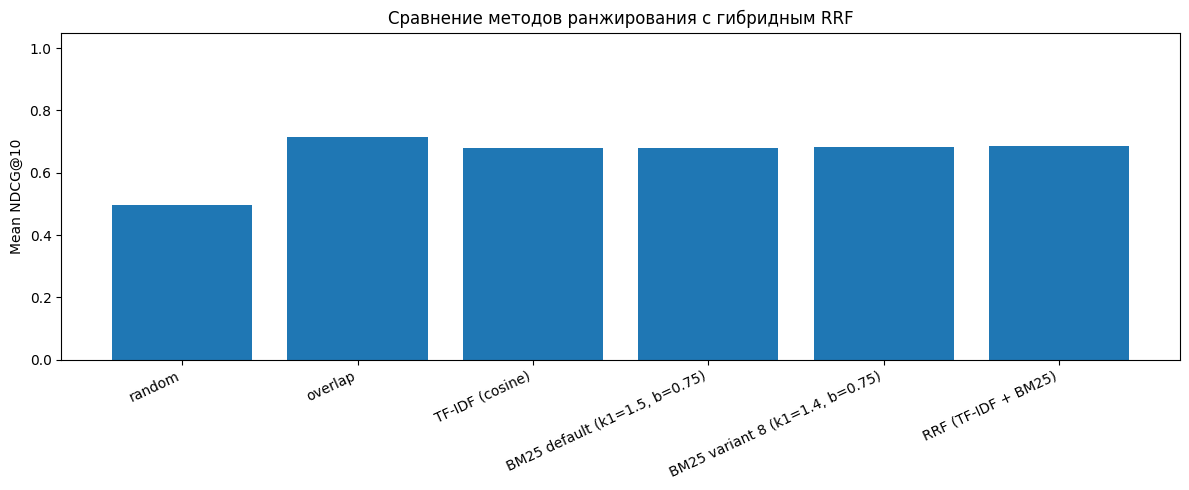


РЕЗУЛЬТАТЫ ДОПОЛНИТЕЛЬНОГО ИССЛЕДОВАНИЯ (NDCG@10):
TF-IDF: 0.6789
BM25 variant: 0.6826
RRF: 0.6842
Вывод: гибридный метод превзошёл оба базовых метода.


In [27]:
# TODO (по желанию): повышенная часть
# ДОПОЛНИТЕЛЬНОЕ ЗАДАНИЕ В: Гибридное ранжирование Reciprocal Rank Fusion

RRF_K = 60

def rrf_scorer(question, candidate_idx):
    """
    Объединяет ранжирования TF-IDF и BM25 variant
    с помощью Reciprocal Rank Fusion.
    """
    candidate_idx = np.asarray(candidate_idx, dtype=int)
    n = len(candidate_idx)

    # Получаем оценки двух алгоритмов
    scores_tfidf = tfidf_scorer(question, candidate_idx)
    scores_bm25 = bm25_variant_scorer(question, candidate_idx)

    # Сортируем кандидатов по убыванию оценок
    order_tfidf = np.argsort(-scores_tfidf, kind="stable")
    order_bm25 = np.argsort(-scores_bm25, kind="stable")

    # Определяем позиции документов в каждой выдаче
    ranks_tfidf = np.empty(n, dtype=int)
    ranks_bm25 = np.empty(n, dtype=int)

    ranks_tfidf[order_tfidf] = np.arange(1, n + 1)
    ranks_bm25[order_bm25] = np.arange(1, n + 1)

    # Рассчитываем итоговую оценку RRF
    rrf_scores = (
        1.0 / (RRF_K + ranks_tfidf)
        + 1.0 / (RRF_K + ranks_bm25)
    )

    return rrf_scores

# Проверяем работу гибридного алгоритма
test_group_info = ELIGIBLE[0]

test_qid = test_group_info["qid"]
test_idx = test_group_info["idx"]
test_question = test_group_info["question"]

test_scores = rrf_scorer(test_question, test_idx)

print("Проверка RRF:")
print("QuestionID:", test_qid)
print("Количество кандидатов:", len(test_scores))
print("Максимальная оценка RRF:", round(test_scores.max(), 6))

# Оцениваем RRF для k=5 и k=10
rrf_rows = []

for cutoff in (5, 10):
    result = evaluate(rrf_scorer, ELIGIBLE, cutoff)

    rrf_rows.append({
        "method": "RRF (TF-IDF + BM25)",
        "k": cutoff,
        "queries": result["queries"],
        "mean_DCG@k": result["mean_DCG"],
        "mean_NDCG@k": result["mean_NDCG"],
    })

rrf_comparison = pd.DataFrame(rrf_rows)

# Добавляем RRF в общую сравнительную таблицу
comparison = pd.concat(
    [comparison, rrf_comparison],
    ignore_index=True
)

print("\nСравнение всех методов с добавлением RRF:")
display(comparison.round(4))

# Строим график для NDCG@10
plot_data = comparison[comparison["k"] == 10]

plt.figure(figsize=(12, 5))
plt.bar(plot_data["method"], plot_data["mean_NDCG@k"])
plt.ylabel("Mean NDCG@10")
plt.title("Сравнение методов ранжирования с гибридным RRF")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

# Сравниваем RRF с TF-IDF и BM25
rrf_value = float(
    comparison[
        (comparison["method"] == "RRF (TF-IDF + BM25)") &
        (comparison["k"] == K)
    ]["mean_NDCG@k"].iloc[0]
)

tfidf_value = metric_value("TF-IDF", K)
bm25_value = metric_value("BM25 variant", K)

print(f"\nРЕЗУЛЬТАТЫ ДОПОЛНИТЕЛЬНОГО ИССЛЕДОВАНИЯ (NDCG@{K}):")
print(f"TF-IDF: {tfidf_value:.4f}")
print(f"BM25 variant: {bm25_value:.4f}")
print(f"RRF: {rrf_value:.4f}")

if rrf_value > max(tfidf_value, bm25_value):
    print("Вывод: гибридный метод превзошёл оба базовых метода.")
elif rrf_value > min(tfidf_value, bm25_value):
    print("Вывод: гибридный метод превзошёл один из базовых методов.")
else:
    print("Вывод: гибридный метод не превзошёл базовые методы.")

**Дополнительное исследование: гибридное ранжирование RRF**

В качестве дополнительного метода был реализован Reciprocal Rank Fusion (RRF), объединяющий результаты ранжирования TF-IDF и BM25 variant 8. Для объединения использовалась константа \(k=60\).

По результатам эксперимента на 243 запросах гибридный метод показал NDCG@10 = 0.6842, что немного выше результатов TF-IDF (0.6789) и BM25 variant 8 (0.6826).

Таким образом, RRF превзошёл оба базовых метода. Это показывает, что объединение двух способов ранжирования может дать небольшой прирост качества за счёт использования их взаимодополняющих результатов.

## 12. Полная самопроверка перед сдачей

In [28]:
# ВЫДАНО: финальная самопроверка
def check_leakage():
    assert check_no_label_leakage(tfidf_scorer, ELIGIBLE), "TF-IDF использует Label"
    assert check_no_label_leakage(bm25_variant_scorer, ELIGIBLE), "BM25 использует Label"


def check_table():
    assert comparison is not None and len(comparison) > 0, \
        "сводная таблица (задание 6) не построена"


def check_source():
    assert DATA_SOURCE != "synthetic", \
        "источник 'synthetic': загрузите настоящий WikiQA-test.tsv"


def check_analysis():
    assert pq_tfidf is not None and pq_bm25 is not None, \
        "per-query анализ (задание 7) не выполнен"


def final_check():
    checks = []
    for name, fn in [("токенизация", test_tokenize),
                     ("TF-IDF", test_tfidf),
                     ("BM25 и параметры варианта", test_bm25),
                     ("DCG/NDCG", test_metrics),
                     ("нет утечки Label", check_leakage),
                     ("сводная таблица", check_table),
                     ("per-query анализ", check_analysis),
                     ("данные — настоящий WikiQA", check_source)]:
        try:
            fn()
            checks.append((name, True, ""))
        except Exception as exc:                      # noqa: BLE001
            checks.append((name, False, f"{type(exc).__name__}: {exc}"))

    print()
    width = max(len(name) for name, _, _ in checks)
    for name, ok, msg in checks:
        print(f"{'[OK]  ' if ok else '[FAIL]'} {name.ljust(width)}  {msg}")
    failed = [name for name, ok, _ in checks if not ok]
    print("\n" + ("Всё готово к сдаче." if not failed
                  else f"Не пройдено: {', '.join(failed)}"))

final_check()

test_tokenize: OK
test_tfidf: OK
test_bm25: OK (максимальное расхождение с эталоном 0.0e+00)
test_metrics: OK (максимальное расхождение с sklearn 3.3e-16)

[OK]   токенизация                
[OK]   TF-IDF                     
[OK]   BM25 и параметры варианта  
[OK]   DCG/NDCG                   
[OK]   нет утечки Label           
[OK]   сводная таблица            
[OK]   per-query анализ           
[OK]   данные — настоящий WikiQA  

Всё готово к сдаче.


### Что сдавать

Репозиторий (или отдельная ветка) со структурой:

```
lab_02/
├── README.md            # ФИО, группа, вариант, метод, результат, вывод
├── lab_02.ipynb         # этот ноутбук, выполненный сверху вниз
├── requirements.txt
└── solution.py          # при необходимости
```

Сам корпус WikiQA в репозиторий **не коммитится** — только код его загрузки
(условия Microsoft Research Data License). Ноутбук должен воспроизводиться после
`pip install -r requirements.txt`.